# Which Factors Track Happiness?

Pearson correlation of each of the report's six factors with the ladder score, with p-values, plus a scatter plot of each factor coloured by region. Each trend line is fitted to its own factor.

In [1]:
import sys
from pathlib import Path

# Make happiness.py importable whether Jupyter starts in JupyterCodes/ or the repo root
for folder in (Path.cwd(), Path.cwd().parent):
    if (folder / "happiness.py").exists():
        sys.path.insert(0, str(folder))
        break

import matplotlib.pyplot as plt
import pandas as pd
import happiness as hp

df = hp.load_data()
print(f"{len(df)} countries, {df[hp.REGION].nunique()} regions")

149 countries, 10 regions


In [2]:
corr = hp.factor_correlations(df)
corr[["factor", "correlation", "p_value"]].style.format({"correlation": "{:.3f}", "p_value": "{:.2e}"})

,factor,correlation,p_value
0,GDP,0.790,5.23e-33
1,Life Expectancy,0.768,2.96e-30
2,Support,0.757,6.05e-29
3,Freedom,0.608,2.05e-16
4,Perception of Corruption,-0.421,8.88e-08
5,Generosity,-0.018,8.29e-01


GDP, life expectancy and social support correlate most strongly with happiness (r ≈ 0.76–0.79). Generosity has no significant relationship (p ≈ 0.83).

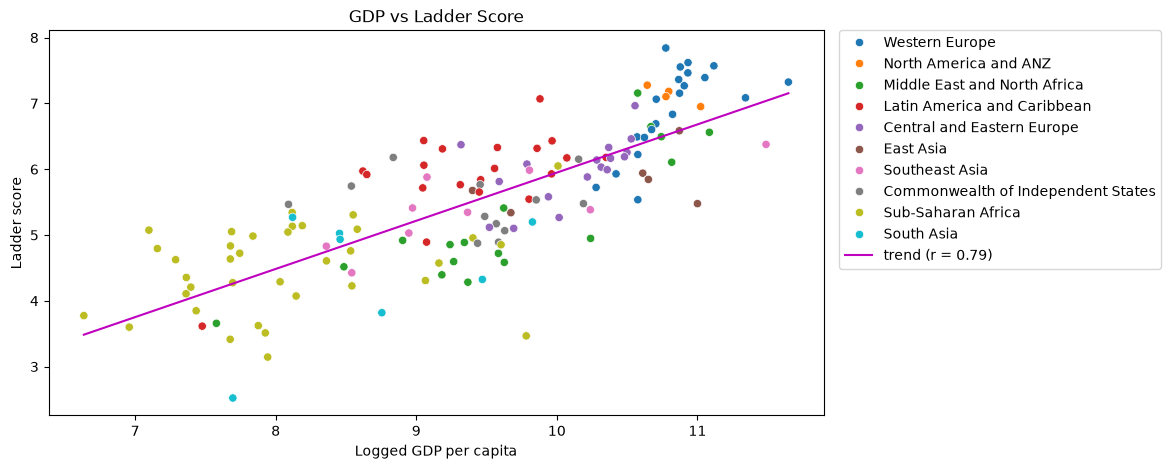

In [3]:
fig = hp.factor_scatter(df, "Logged GDP per capita")
hp.save(fig, "GDP.png")
plt.show()

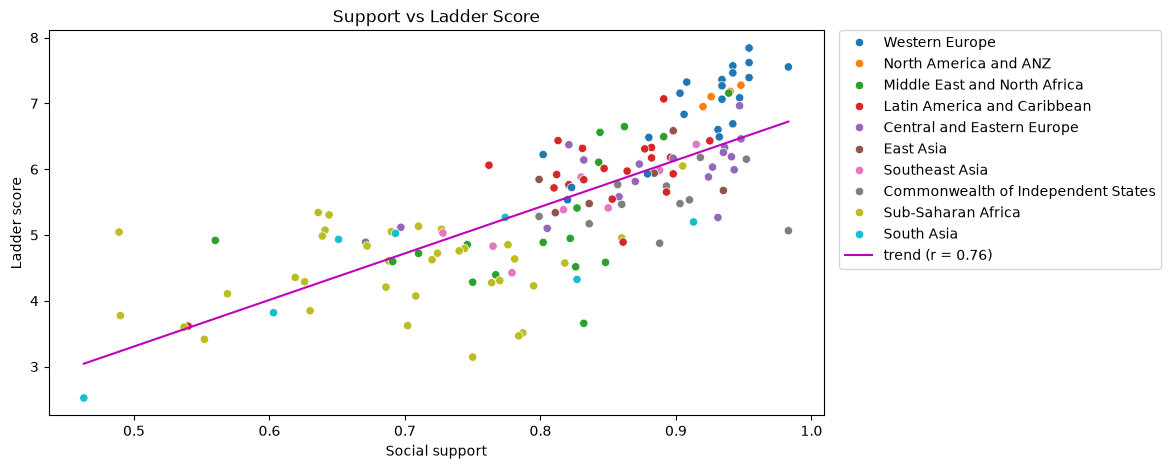

In [4]:
fig = hp.factor_scatter(df, "Social support")
hp.save(fig, "Support.png")
plt.show()

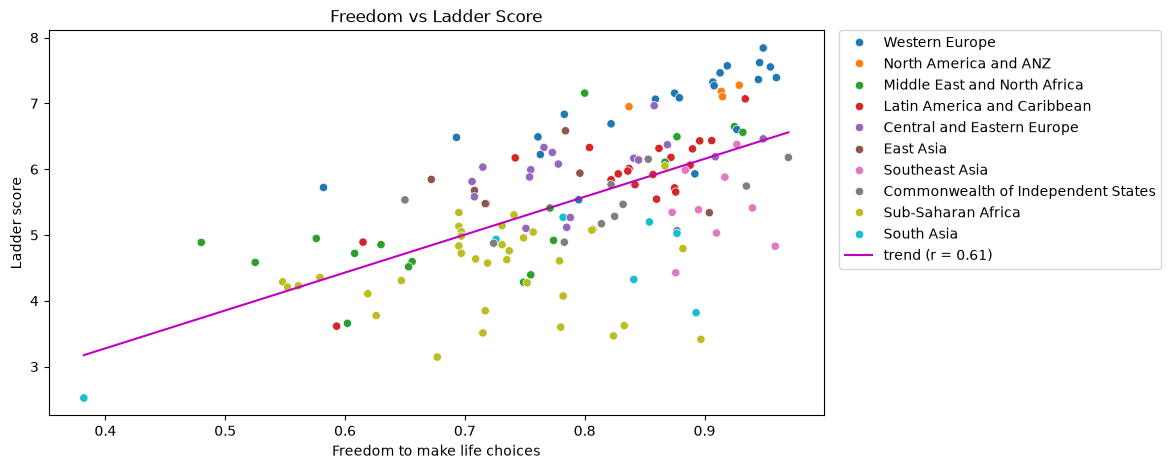

In [5]:
fig = hp.factor_scatter(df, "Freedom to make life choices")
hp.save(fig, "Freedom.png")
plt.show()

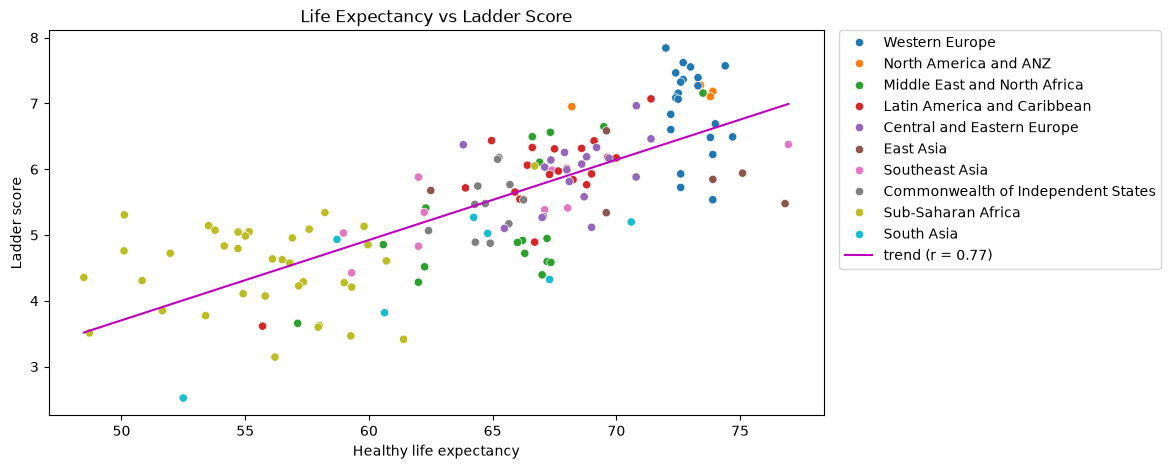

In [6]:
fig = hp.factor_scatter(df, "Healthy life expectancy")
hp.save(fig, "Life Expectancy.png")
plt.show()

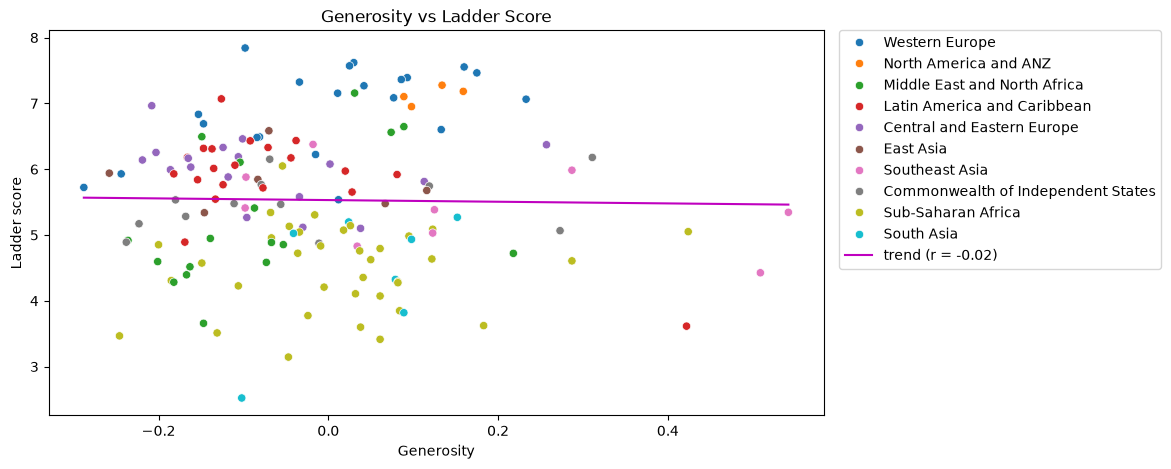

In [7]:
fig = hp.factor_scatter(df, "Generosity")
hp.save(fig, "Generosity.png")
plt.show()

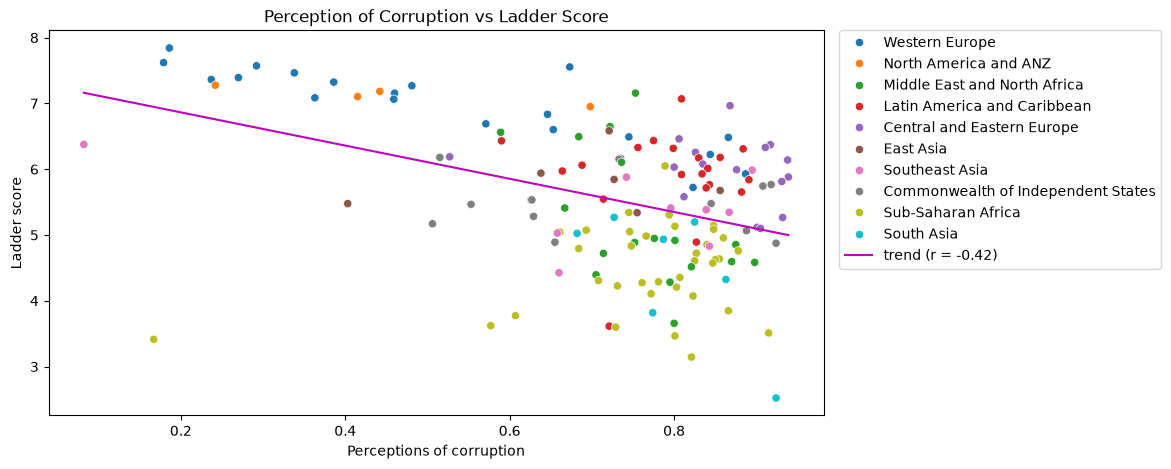

In [8]:
fig = hp.factor_scatter(df, "Perceptions of corruption")
hp.save(fig, "Corruption.png")
plt.show()

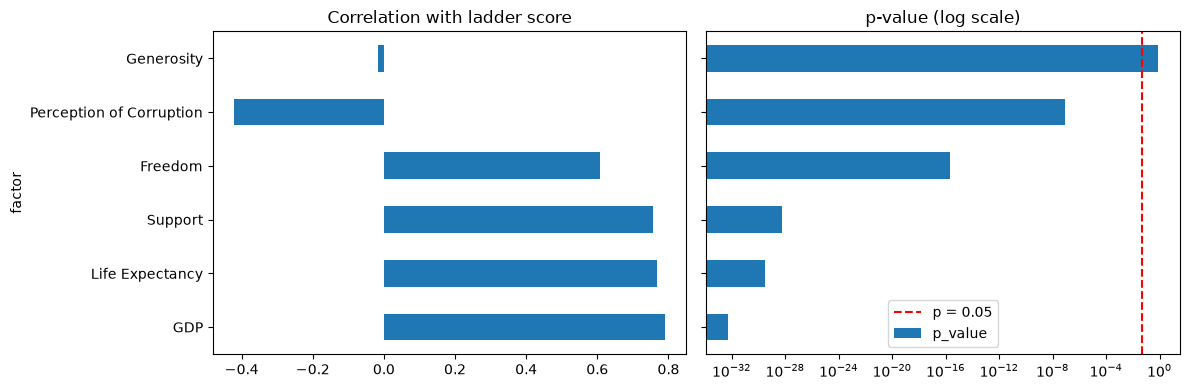

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
corr.plot.barh(x="factor", y="correlation", ax=axes[0], legend=False, title="Correlation with ladder score")
corr.plot.barh(x="factor", y="p_value", ax=axes[1], legend=False, logx=True, title="p-value (log scale)")
axes[1].axvline(0.05, color="red", linestyle="--", label="p = 0.05")
axes[1].legend()
plt.tight_layout()
plt.show()